[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aranaur/aranaur.rbind.io/blob/main/lectures/kse/MATH840/26autumn/labs/_demo10_uk.ipynb)

# MATH840 — Практика тижня 10: фундаментальні моделі проти всього, що ви знаєте

**Не оцінюється.** Десять тижнів тому ви почали із сезонного наївного прогнозу. Відтоді були ETS,
ARIMA, Prophet, комбінації, нейромережі. Сьогодні з ними зустрічаються новачки — **моделі, які ніколи не
бачили вашого ряду і взагалі на ньому не навчаються**. Ті самі вікна, ті самі правила.

| | Історія | Питання | Хв |
|---|---|---|---:|
| 1 | ⚡ Електрика Мельбурна: реванш | чи може модель без навчання обіграти налаштований Prophet минулого тижня? | 20 |
| 2 | 🏆 300 рядів зі змагання M3 | хто виграє на багатьох рядах — і якою ціною? | 20 |
| 3 | 🎯 ті самі 300 рядів | чий 80% інтервал чесний? | 10 |
| 4 | 📏 короткі ряди | скільки минулого потрібно кожній моделі? | 10 |
| 5 | 🍽️ один ряд, усі моделі | сьогоднішня лабораторна на відкритому ряді | 20 |

🔮 — здогадка: запишіть її до того, як запустите клітинку. ❓ — питання до аудиторії.

**Запустіть ноутбук до заняття** (`Runtime → Run all`, близько пів години на безкоштовному CPU в Colab):
під час першого запуску моделі завантажують близько 1,5 ГБ.

## 0. Налаштування

In [1]:
!pip install -q statsforecast==2.1.1 neuralforecast==3.3.0 chronos-forecasting==2.3.2 "timesfm[torch]==3.0.2" tirex-ts==1.4.2 great_tables

import os
os.environ["NIXTLA_ID_AS_COL"] = "true"
import logging
import time
import warnings
warnings.filterwarnings("ignore")
for name in ("cmdstanpy", "prophet", "lightning", "lightning.pytorch", "pytorch_lightning", "transformers"):
    logging.getLogger(name).setLevel(logging.CRITICAL)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from great_tables import GT, loc, style
from matplotlib.colors import LinearSegmentedColormap, to_hex
from prophet import Prophet
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, AutoTheta, MSTL, SeasonalNaive

DEVICE = "cpu"              # "cuda" on a GPU runtime; every timing below is for this device
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 120, "display.precision", 3)
BASE = ("https://raw.githubusercontent.com/Aranaur/aranaur.rbind.io/"
        "main/lectures/kse/MATH840/26autumn/data")
COLOURS = {"actual": "#314f4f", "fm": "#e64173", "old": "#9aa5a5", "nn": "#6A5ACD", "b": "#20B2AA", "c": "#FFA500"}

### Чотири фундаментальні моделі, один інтерфейс

Кожна модель отримує список історій і повертає для кожного ряду медіану та квантилі 10% і 90% — тобто
80% інтервал без жодних зусиль. **Жодного навчання**: моделі приходять уже навченими.

| Модель | Звідки | Розмір | Усередині |
|---|---|---|---|
| Chronos-Bolt (small) | Amazon, 2024 | 48M | енкодер–декодер T5, ряд нарізаний на патчі |
| Chronos-2 | Amazon, 2025 | 120M | енкодер з увагою між рядами й коваріатами |
| TimesFM 2.5 | Google, 2025 | 200M | трансформер-декодер, довгі вихідні патчі |
| TiRex | NX-AI, 2025 | 35M | xLSTM — рекурентна мережа, а не трансформер |

In [2]:
from chronos import BaseChronosPipeline
import timesfm
import tirex

bolt = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map=DEVICE)
chronos2 = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)
tfm = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
tfm.model.device, tfm.model.device_count = torch.device(DEVICE), 1      # keep TimesFM on DEVICE too
tfm.model.to(DEVICE)
tfm.compile(timesfm.ForecastConfig(max_context=512, max_horizon=128, normalize_inputs=True,
                                   use_continuous_quantile_head=True, fix_quantile_crossing=True))
tirex_model = tirex.load_model("NX-AI/TiRex", device=DEVICE)


def foundation(name, histories, h):
    # -> (median, 10% quantile, 90% quantile), each an array of shape (number of series, h)
    contexts = [torch.tensor(np.asarray(x, float), dtype=torch.float32) for x in histories]
    if name in ("Chronos-Bolt", "Chronos-2"):
        pipe = bolt if name == "Chronos-Bolt" else chronos2
        q, _ = pipe.predict_quantiles(contexts, prediction_length=h, quantile_levels=[0.1, 0.5, 0.9])
        q = np.stack([np.asarray(a).reshape(-1, h, 3)[0] for a in q])     # Chronos-2 adds a variate axis
        return q[:, :, 1], q[:, :, 0], q[:, :, 2]
    if name == "TimesFM 2.5":
        _, q = tfm.forecast(horizon=h, inputs=[c.numpy() for c in contexts])
        q = np.asarray(q)[:, :h]                                           # mean, then 10%, 20%, ..., 90%
        return q[:, :, 5], q[:, :, 1], q[:, :, 9]
    q, _ = tirex_model.forecast(context=contexts, prediction_length=h)
    q = np.asarray(q)                                                      # 10%, 20%, ..., 90%
    return q[:, :, 4], q[:, :, 0], q[:, :, 8]


FOUNDATION = ["Chronos-Bolt", "Chronos-2", "TimesFM 2.5", "TiRex"]

In [3]:
_shade = LinearSegmentedColormap.from_list("shade", ["#bfe0b0", "#ffffff", "#f5b8cb"])


def scoreboard(table, rules=None, decimals=2):
    # Green is better, pink is worse, the best in bold. A rule is "lower", "higher" or a target value.
    df = table.to_frame() if isinstance(table, pd.Series) else table.copy()
    df.index, df.columns = df.index.map(str), df.columns.map(str)
    rules = rules or {c: "lower" for c in df.columns}
    gt = (GT(df.reset_index(names=" "), rowname_col=" ")
          .fmt_number(columns=list(df.select_dtypes("number").columns), decimals=decimals)
          .sub_missing(missing_text=""))
    for c, rule in rules.items():
        v = df[c].astype(float)
        bad = v if rule == "lower" else -v if rule == "higher" else (v - rule).abs()
        lo, hi = bad.min(), bad.max()
        for i, b in enumerate(bad):
            if np.isnan(b):
                continue
            look = [style.fill(color=to_hex(_shade((b - lo) / (hi - lo) if hi > lo else 0.0)))]
            gt = gt.tab_style(style=look + ([style.text(weight="bold")] if b == lo else []),
                              locations=loc.body(columns=c, rows=[i]))
    return gt


def barh(means, title, xlabel, colour_of, hatch=lambda name: False):
    # One horizontal bar per model, best at the top.
    means = means.sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(10, 0.36 * len(means) + 1.2))
    bars = ax.barh(means.index, means, color=[colour_of(n) for n in means.index])
    for bar, name in zip(bars, means.index):
        if hatch(name):
            bar.set_hatch("//")
            bar.set_edgecolor("white")
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.show()

## 1. ⚡ Електрика Мельбурна: реванш

Минулого тижня ви були диспетчером енергомережі Вікторії. Після години роботи — два сезони, свята з
назвами, вікно навколо Різдва, температура та її квадрат — Prophet дійшов до середнього MASE **0,54** без
погоди і **0,40** з температурою, яка справді була.

Сьогодні модель, яка цього ряду ніколи не бачила, отримує три рядки коду.

In [4]:
vic = pd.read_csv(f"{BASE}/vic_elec.csv", parse_dates=["ds"])
wide = vic.pivot_table(index="ds", columns="unique_id", values="y")
holiday = vic.query("unique_id == 'Demand'").set_index("ds")["Holiday"].astype(bool)
elec = pd.DataFrame({"y": wide["Demand"].resample("D").sum() / 2e3,      # half-hourly MW -> GWh per day
                     "temp": wide["Temperature"].resample("D").max(),
                     "holiday": holiday.resample("D").max().astype(float)}).reset_index()
elec["unique_id"] = "Victoria"
y1 = elec["y"].to_numpy()
H1 = 28

### 1.1 Три рядки, жодного навчання

Останні чотири тижні 2014 року, разом із Різдвом, з усього, що було до них.

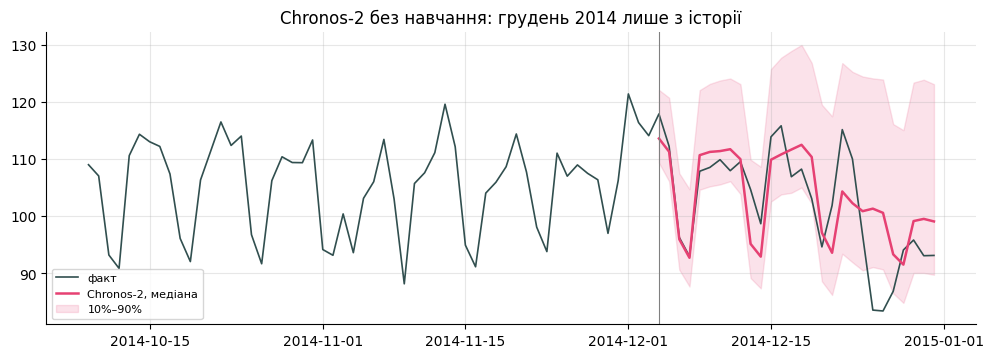

In [5]:
e = len(y1) - H1
median, low, high = foundation("Chronos-2", [y1[:e]], H1)

days = elec["ds"].iloc[e:]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(elec["ds"].iloc[e - 56:], y1[e - 56:], color=COLOURS["actual"], linewidth=1.2, label="факт")
ax.plot(days, median[0], color=COLOURS["fm"], linewidth=1.8, label="Chronos-2, медіана")
ax.fill_between(days, low[0], high[0], color=COLOURS["fm"], alpha=0.15, label="10%–90%")
ax.axvline(days.iloc[0], color="grey", linewidth=0.8)
ax.set_title("Chronos-2 без навчання: грудень 2014 лише з історії")
ax.legend(loc="lower left", fontsize=8)
plt.show()

### 1.2 Реванш на дев'яти вікнах минулого тижня

Ті самі дев'ять чотиритижневих вікон, що й минулого тижня, з квітня по грудень 2014. З одного боку —
найкращі моделі минулого тижня (тут їх перебудовано), з другого — чотири фундаментальні моделі, а також
Chronos-2 з тими самими коваріатами, що й у Prophet: ознакою свята і температурою (справжньою, тобто
ex post, як у Prophet).

🔮 **Спершу вгадайте.** Чи дотягне хоч одна модель без навчання до 0,54 Prophet? До його 0,40 з погодою?

In [6]:
origins1 = [len(y1) - H1 * k for k in range(9, 0, -1)]
scale1 = np.mean(np.abs(y1[7:origins1[0]] - y1[:origins1[0] - 7]))
holidays = pd.DataFrame({"holiday": "public holiday", "ds": elec.loc[elec["holiday"] == 1, "ds"]})


def prophet_elec(weather):
    def forecast(e):
        model = Prophet(daily_seasonality=False, holidays=holidays)
        if weather:
            for column in ("temp", "temp2"):
                model.add_regressor(column)
        data = elec.assign(temp2=elec["temp"] ** 2)
        model.fit(data.iloc[:e])
        return model.predict(data.iloc[e:e + H1])["yhat"].to_numpy()
    return forecast


def chronos2_with(columns):
    def forecast(e):
        out = chronos2.predict_df(elec.iloc[:e][["unique_id", "ds", "y"] + columns],
                                  future_df=elec.iloc[e:e + H1][["unique_id", "ds"] + columns],
                                  id_column="unique_id", timestamp_column="ds", target="y",
                                  prediction_length=H1, quantile_levels=[0.5])
        return out["predictions"].to_numpy()
    return forecast


forecasters1 = {
    "seasonal naive": lambda e: np.tile(y1[e - 7:e], 4),
    "MSTL (7, 365)": lambda e: MSTL(season_length=[7, 365]).fit(y=y1[:e]).predict(h=H1)["mean"],
    "Prophet + holidays": prophet_elec(False),
    "Prophet + holidays + temperature": prophet_elec(True),
    **{name: (lambda name: lambda e: foundation(name, [y1[:e]], H1)[0][0])(name) for name in FOUNDATION},
    "Chronos-2 + holidays + temperature": chronos2_with(["holiday", "temp"]),
}

scores1, seconds1 = {}, {}
for name, f in forecasters1.items():
    start = time.time()
    scores1[name] = [np.mean(np.abs(y1[e:e + H1] - np.asarray(f(e)))) / scale1 for e in origins1]
    seconds1[name] = time.time() - start
scores1 = pd.DataFrame(scores1, index=[f"{elec['ds'][e]:%d %b}" for e in origins1]).T
scores1["mean"] = scores1.mean(axis=1)
scores1["seconds"] = pd.Series(seconds1)
scoreboard(scores1)

,24 Apr,22 May,19 Jun,17 Jul,14 Aug,11 Sep,09 Oct,06 Nov,04 Dec,mean,seconds
seasonal naive,1.34,0.98,0.56,0.48,1.10,0.56,0.62,0.95,1.25,0.87,0.00
"MSTL (7, 365)",0.78,0.55,0.69,0.56,0.59,0.31,0.45,0.58,0.86,0.60,5.38
Prophet + holidays,0.60,0.59,0.58,0.79,0.37,0.41,0.33,0.51,0.81,0.55,2.31
Prophet + holidays + temperature,0.43,0.31,0.39,0.65,0.27,0.32,0.34,0.38,0.46,0.40,2.62
Chronos-Bolt,0.70,0.33,0.65,0.50,0.37,0.45,0.43,0.64,0.97,0.56,0.37
Chronos-2,0.63,0.26,0.59,0.60,0.37,0.39,0.41,0.56,0.70,0.50,2.27
TimesFM 2.5,0.41,0.21,0.28,0.35,0.20,0.27,0.31,0.30,0.44,0.31,2.56
TiRex,0.62,0.26,0.58,0.58,0.36,0.42,0.37,0.57,0.96,0.52,10.31
Chronos-2 + holidays + temperature,0.56,0.24,0.42,0.61,0.24,0.33,0.50,0.46,0.60,0.44,5.71


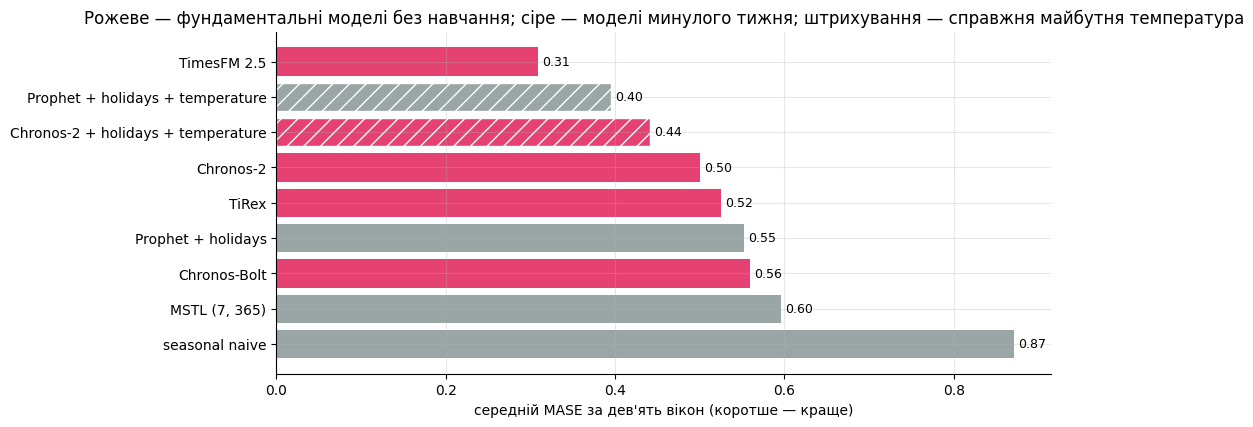

In [7]:
barh(scores1["mean"], "Рожеве — фундаментальні моделі без навчання; сіре — моделі минулого тижня; штрихування — справжня майбутня температура",
     "середній MASE за дев'ять вікон (коротше — краще)",
     lambda n: COLOURS["fm"] if n.split(" +")[0] in FOUNDATION else COLOURS["old"],
     hatch=lambda n: "temperature" in n)

**📌 Що показав реванш.**

- **Без жодного навчання** Chronos-2 (0,50), TiRex (0,52) і Chronos-Bolt (0,56) стали поруч із Prophet + свята (0,55) або випередили його, хоча на Prophet ми минулого тижня витратили годину. MSTL (0,60) позаду всіх, крім сезонного наївного.
- **Chronos-2 з тими самими коваріатами (0,44)** наблизився до Prophet із погодою (0,40), але не обіграв його. Знання про світ, яке Prophet отримав від нас руками, Chronos-2 мусить вивести з тих самих стовпців.
- **TimesFM 2.5 — 0,31**, далеко попереду всіх, зокрема моделей, які бачили справжню майбутню температуру. У грудневому вікні вона має 0,44 там, де Chronos-2 — 0,70.
- **Ціна:** кожна фундаментальна модель — секунди на всі дев'ять вікон.

Модель, що не бачила ні температури, ні свят, обіграла модель, яка бачила обидва, ще й з фактичною погодою. Таке має насторожити.

### 1.3 Надто добре, щоб бути правдою?

Одна модель обіграла Prophet **зі справжньою погодою**, хоча бачила лише сам попит. Перш ніж
святкувати, зробімо те, що вимагає чекліст лекції: **перевіримо корпус.** Що про навчальні дані пише
документація кожної моделі:

| Модель | Навчальні дані, як опубліковано | Чи є там попит на електрику в Австралії? |
|---|---|---|
| Chronos-Bolt | не розкрито; картка моделі каже, що бенчмарк II Chronos, куди входить *Australian Electricity*, вона **не** бачила | імовірно, ні |
| Chronos-2 | технічний звіт, таблиця 6: 22 реальні набори, жодного австралійського | **ні** |
| TiRex | стаття, таблиці 5–6: підмножини Chronos і GIFT-Eval, жодного австралійського | ні (версія 1.0) |
| TimesFM 2.5 | картка моделі: *GiftEvalPretrain*, до списку якого (стаття GIFT-Eval, таблиця 14) входить **Australian Electricity Demand** з репозиторію Monash — півгодинний попит п'яти штатів, серед них Вікторії, 2002–2015 — і ще один ряд Monash, *Elecdemand* | **так** |

Наш добовий попит 2012–2014 — це та сама електрика, лише підсумована за день.

**❓ Питання.** Чи доводить це, що TimesFM «запам'ятала» грудень 2014? Що треба побачити, щоб відрізнити
пам'ять від майстерності? І що це означає для 0,31?

**📌 Відповідь.** Ні, не доводить: TimesFM може бути просто сильною моделлю. Але довіряти 0,31 як оцінці zero-shot ми вже не можемо. Модель вчилася на півгодинному попиті тих самих штатів за ті самі роки, тож наш тест для неї не «невидимий».

Як відрізнити пам'ять від майстерності:

- **дані, новіші за модель**: TimesFM 2.5 вийшла у 2025 році. На попиті 2026 року пам'ять не допоможе;
- **тест пам'яті з лекції**: порівняти перевагу моделі на рядах, які вона бачила, з перевагою на тих, яких не бачила;
- **порівняння з чистою моделлю**: Chronos-2 цих даних не бачила, і її 0,50 — це чесне число для цього ряду.

У звіті 0,31 можна навести лише з примітками «корпус містить ці дані» та «оцінка оптимістична» — або не наводити зовсім.

## 2. 🏆 300 рядів зі змагання M3

Один ряд — одна історія, і, як ми щойно бачили, можливо, запам'ятована. Тепер ширина: 300 місячних рядів
зі змагання M3 (1999), прогноз на 18 місяців — горизонт самого змагання.

Щодо корпусу: **M3 є в навчальному списку GIFT-Eval, на якому вчилася TimesFM 2.5**, і немає в жодній з
трьох інших (Chronos-2 — таблиця 6, TiRex — таблиці 5–6; картка Chronos-Bolt каже, що бенчмарк з M3 вона
не бачила). Рядок TimesFM нижче позначено †.

Учасники — від тижня 1 до сьогодні:

- **сезонний наївний**, **ETS**, **ARIMA**, **Theta** і **середнє ETS, ARIMA та Theta** (урок тижня 9);
- **N-BEATS** і **MLP** з тижня 9, навчені тут з нуля на 300 історіях (глобальна модель);
- чотири **фундаментальні моделі** без навчання і **середнє трьох найновіших**.

In [8]:
m3 = pd.read_csv(f"{BASE}/m3_monthly.csv", parse_dates=["ds"])
ids = np.random.default_rng(1).choice(m3["unique_id"].unique(), 300, replace=False)
panel = m3[m3["unique_id"].isin(ids)].sort_values(["unique_id", "ds"])
H2 = 18
test2 = panel.groupby("unique_id").tail(H2)
train2 = panel.drop(test2.index)
histories2 = [g["y"].to_numpy() for _, g in train2.groupby("unique_id")]
actual2 = np.stack([g["y"].to_numpy() for _, g in test2.groupby("unique_id")])
scale2 = np.array([np.mean(np.abs(x[12:] - x[:-12])) for x in histories2])
print(f"{len(histories2)} рядів, від {min(map(len, histories2))} до {max(map(len, histories2))} місяців історії")

300 рядів, від 50 до 126 місяців історії


In [9]:
point2, band2, seconds2 = {}, {}, {}

start = time.time()
sf = StatsForecast(models=[SeasonalNaive(12, alias="seasonal naive"), AutoETS(season_length=12, alias="ETS"),
                           AutoARIMA(season_length=12, alias="ARIMA"), AutoTheta(season_length=12, alias="Theta")],
                   freq="MS", n_jobs=-1)
classic = sf.forecast(df=train2, h=H2, level=[80]).sort_values(["unique_id", "ds"])
seconds2["ETS, ARIMA, Theta, naive (together)"] = time.time() - start
for name in ["seasonal naive", "ETS", "ARIMA", "Theta"]:
    point2[name] = classic[name].to_numpy().reshape(-1, H2)
    band2[name] = (classic[f"{name}-lo-80"].to_numpy().reshape(-1, H2), classic[f"{name}-hi-80"].to_numpy().reshape(-1, H2))
point2["average: ETS, ARIMA, Theta"] = (point2["ETS"] + point2["ARIMA"] + point2["Theta"]) / 3

In [10]:
from neuralforecast import NeuralForecast
from neuralforecast.models import MLP, NBEATS, LSTM

NEURAL = dict(max_steps=500, scaler_type="robust", random_seed=1, accelerator="gpu" if DEVICE == "cuda" else "cpu",
              devices=1, enable_progress_bar=False, enable_model_summary=False, logger=False)
for name, model in [("N-BEATS (trained here)", NBEATS(h=H2, input_size=36, **NEURAL)),
                    ("MLP (trained here)", MLP(h=H2, input_size=36, **NEURAL))]:
    start = time.time()
    nf = NeuralForecast(models=[model], freq="MS")
    nf.fit(df=train2)
    point2[name] = nf.predict().sort_values(["unique_id", "ds"])[type(model).__name__].to_numpy().reshape(-1, H2)
    seconds2[name] = time.time() - start

for name in FOUNDATION:
    start = time.time()
    median, low, high = foundation(name, histories2, H2)
    seconds2[name] = time.time() - start
    point2[name], band2[name] = median, (low, high)
point2["average: Chronos-2, TimesFM, TiRex"] = (point2["Chronos-2"] + point2["TimesFM 2.5"] + point2["TiRex"]) / 3

🔮 **Спершу вгадайте.** Розставте за місцями. Де опиняться нейромережі, навчені на цих 300 рядах, проти
моделей, які їх ніколи не бачили? Чи встоїть старе середнє ETS, ARIMA і Theta?

In [11]:
mase2 = pd.DataFrame({name: np.mean(np.abs(actual2 - f), axis=1) / scale2 for name, f in point2.items()})
mase2 = mase2.rename(columns={"TimesFM 2.5": "TimesFM 2.5 †"})
board2 = pd.DataFrame({"mean MASE": mase2.mean(), "median MASE": mase2.median(),
                       "beats ETS": mase2.lt(mase2["ETS"], axis=0).mean(),
                       "worst series": mase2.max()}).sort_values("mean MASE")
scoreboard(board2, rules={"mean MASE": "lower", "median MASE": "lower", "beats ETS": "higher", "worst series": "lower"})

,mean MASE,median MASE,beats ETS,worst series
"average: Chronos-2, TimesFM, TiRex",0.84,0.68,0.63,5.24
Chronos-2,0.85,0.69,0.61,4.93
TimesFM 2.5 †,0.86,0.71,0.58,5.61
TiRex,0.86,0.70,0.58,5.16
"average: ETS, ARIMA, Theta",0.88,0.71,0.59,5.09
ETS,0.90,0.71,0.00,4.91
Theta,0.91,0.73,0.48,5.02
ARIMA,0.94,0.75,0.48,5.34
Chronos-Bolt,0.94,0.75,0.46,5.28
MLP (trained here),0.96,0.77,0.43,5.29


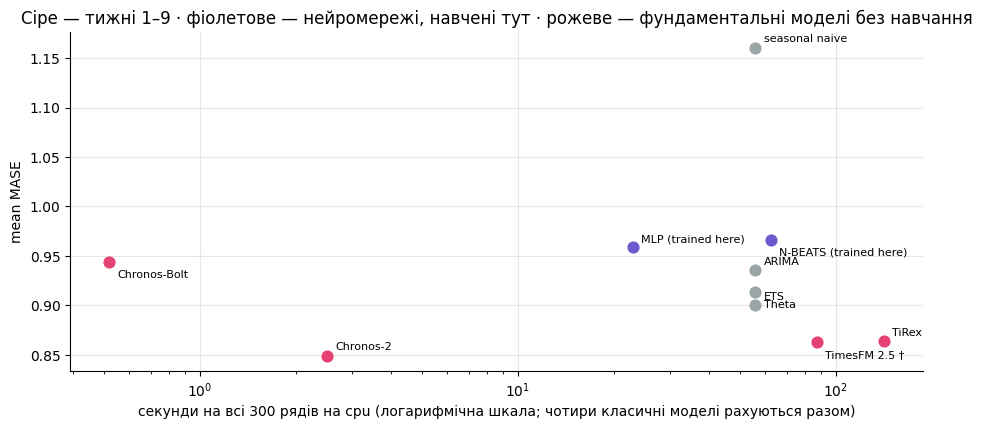

In [12]:
def family(name):
    if name.startswith(("N-BEATS", "MLP")):
        return COLOURS["nn"]
    return COLOURS["fm"] if any(name.startswith(f) for f in FOUNDATION) or "Chronos-2, TimesFM" in name else COLOURS["old"]


timing = {"seasonal naive": "ETS, ARIMA, Theta, naive (together)", "ETS": "ETS, ARIMA, Theta, naive (together)",
          "ARIMA": "ETS, ARIMA, Theta, naive (together)", "Theta": "ETS, ARIMA, Theta, naive (together)"}
fig, ax = plt.subplots(figsize=(11, 4.4))
for i, name in enumerate(board2.index):
    key = timing.get(name, name.replace(" †", ""))
    if key not in seconds2:
        continue
    ax.scatter(seconds2[key], board2.loc[name, "mean MASE"], s=60, color=family(name), zorder=3)
    ax.annotate(name, (seconds2[key], board2.loc[name, "mean MASE"]), xytext=(6, 4 if i % 2 else -11),
                textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel(f"секунди на всі 300 рядів на {DEVICE} (логарифмічна шкала; чотири класичні моделі рахуються разом)")
ax.set_ylabel("mean MASE")
ax.set_title("Сіре — тижні 1–9 · фіолетове — нейромережі, навчені тут · рожеве — фундаментальні моделі без навчання")
plt.show()

**📌 Що показав турнір.**

- **Нагорі всі три нові фундаментальні моделі та їхнє середнє** (0,84–0,86). Найкраща класика — середнє ETS, ARIMA і Theta (0,88), ETS — 0,90. Перевага реальна, але скромна: близько 5%, і ETS вони обігрують приблизно на 60% рядів, а не на всіх.
- **TimesFM† могла бачити M3, але не краща за Chronos-2**, яка M3 не бачила. Тут сліду пам'яті немає — на відміну від електрики. Позначка † нагадує не про шахрайство, а про те, що чистоти тесту ніхто не гарантує.
- **Chronos-Bolt (0,94)** — на рівні ARIMA. Покоління 2024 і 2025 років помітно різняться.
- **Нейромережі, навчені тут (0,96–0,97)**, гірші за ETS, хоча бачили саме ці 300 рядів.
- **Ціна:** Chronos-2 рахує всі 300 рядів за кілька секунд. TimesFM і TiRex на CPU працюють десятки секунд — довше, ніж ETS, ARIMA і Theta разом.
- **«Найгірший ряд» близько 5 у всіх**: є ряди, які не прогнозує ніхто.

**❓ Питання.** Мережі, які ви навчили на 300 рядах, програли моделям, яким ці ряди ніколи не показували.
Чи це вирок нейромережам?

**📌 Відповідь.** Ні. Це вирок навчанню з нуля на малих даних:

- 300 рядів по 50–126 місяців — це небагато для мережі, яка починає з випадкових ваг;
- 500 кроків навчання, стандартна архітектура, жодного налаштування;
- N-BEATS виграла M4, навчаючись на 100 000 рядів, та ще й ансамблем із сотень моделей.

А фундаментальні моделі — **теж нейромережі**. Вони вже пройшли навчання на мільярдах спостережень, тож ви отримуєте результат того навчання безкоштовно. Мораль не «мережі погані», а «мережам потрібні дані, і фундаментальна модель — це мережа, яка їх уже отримала».

## 3. 🎯 Чий 80% інтервал чесний?

Прогнозу, за яким ухвалюють рішення, потрібен діапазон. ETS, ARIMA і Theta дають інтервали зі своїх
рівнянь (тижні 6–8), фундаментальні моделі — квантилі, яких навчилися. На тих самих 300 × 18 місяцях:
як часто факт потрапляє всередину і який показник Вінклера (тиждень 8: ширина плюс штраф за кожен
промах)?

🔮 **Спершу вгадайте.** Чиї інтервали завузькі?

In [13]:
rows = {}
for name, (lo, hi) in band2.items():
    inside = (actual2 >= lo) & (actual2 <= hi)
    winkler = ((hi - lo) + 10 * (np.maximum(lo - actual2, 0) + np.maximum(actual2 - hi, 0))) / scale2[:, None]
    rows[name + (" †" if name == "TimesFM 2.5" else "")] = {
        "coverage": inside.mean(), "coverage, months 1–6": inside[:, :6].mean(),
        "coverage, months 13–18": inside[:, 12:].mean(), "Winkler": winkler.mean()}
intervals2 = pd.DataFrame(rows).T.sort_values("Winkler")
scoreboard(intervals2, rules={"coverage": 0.8, "coverage, months 1–6": 0.8, "coverage, months 13–18": 0.8, "Winkler": "lower"})

,coverage,"coverage, months 1–6","coverage, months 13–18",Winkler
TimesFM 2.5 †,0.79,0.83,0.74,4.19
TiRex,0.81,0.80,0.78,4.21
Chronos-2,0.76,0.77,0.73,4.22
ETS,0.74,0.78,0.70,4.38
Chronos-Bolt,0.79,0.80,0.76,4.59
Theta,0.71,0.75,0.65,4.68
ARIMA,0.76,0.79,0.71,4.69
seasonal naive,0.80,0.83,0.78,5.68


**📌 Що з інтервалами.**

- **Класичні інтервали завузькі:** ETS покриває 74%, ARIMA — 76%, Theta — 71%. На далекому горизонті (місяці 13–18) — лише 65–71%. Рівняння моделей не знають, що модель могла бути неправильною.
- **Фундаментальні моделі ближчі до 80%:** TiRex 81%, TimesFM 79%, Chronos-Bolt 79%, Chronos-2 76%. За Вінклером найкращі три нові моделі (4,19–4,22) проти 4,38 в ETS.
- **Сезонний наївний покриває рівно 80%, але має найгірший Вінклер (5,68):** він «чесний», бо дуже широкий. Тому покриття без Вінклера нічого не каже.
- Chronos-Bolt має добре покриття, але гірший Вінклер (4,59): її інтервали ширші, ніж потрібно.

## 4. 📏 Скільки минулого потрібно кожній моделі?

Справжні ряди часто короткі: новий товар, новий магазин, нова країна. ETS мусить оцінити все з того, що
їй дали. Фундаментальна модель приносить свій досвід із собою.

Обрізаємо ті самі 150 рядів до останніх 24, 36 або 60 місяців історії і прогнозуємо ті самі 18 місяців.

🔮 **Спершу вгадайте.** Коли історії лише два роки, кому гірше — ETS чи фундаментальним моделям?

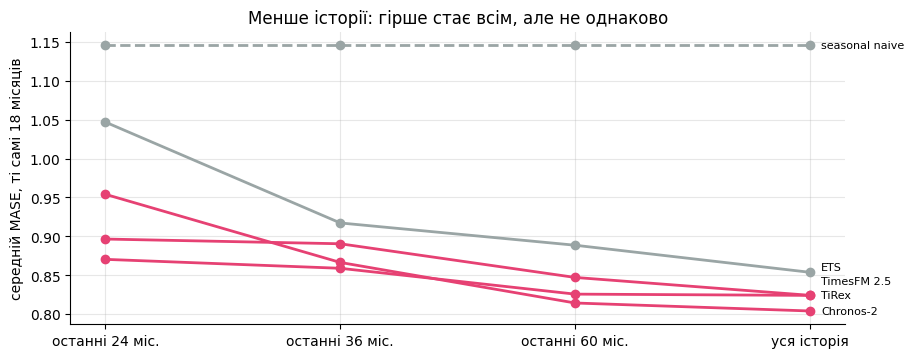

,останні 24 міс.,останні 36 міс.,останні 60 міс.,уся історія
Chronos-2,0.95,0.87,0.81,0.80
ETS,1.05,0.92,0.89,0.85
TiRex,0.87,0.86,0.83,0.82
TimesFM 2.5,0.90,0.89,0.85,0.82
seasonal naive,1.15,1.15,1.15,1.15


In [14]:
subset = slice(0, 150)
rows = []
label_of = lambda keep: f"останні {keep} міс." if keep else "уся історія"
for keep in [24, 36, 60, None]:
    cut = [x[-keep:] if keep else x for x in histories2[subset]]
    label = label_of(keep)
    sf_cut = pd.concat([pd.DataFrame({"unique_id": i, "ds": pd.date_range("2000-01-01", periods=len(x), freq="MS"), "y": x})
                        for i, x in enumerate(cut)])
    ets = AutoETS(season_length=12)
    fc = StatsForecast(models=[ets], freq="MS", n_jobs=-1).forecast(df=sf_cut, h=H2).sort_values(["unique_id", "ds"])
    found = {"ETS": fc["AutoETS"].to_numpy().reshape(-1, H2), "seasonal naive": np.stack([np.tile(x[-12:], 2)[:H2] for x in cut])}
    for name in ["Chronos-2", "TimesFM 2.5", "TiRex"]:
        found[name] = foundation(name, cut, H2)[0]
    for name, f in found.items():
        rows.append({"history": label, "model": name,
                     "mean MASE": np.mean(np.mean(np.abs(actual2[subset] - f), axis=1) / scale2[subset])})
context = pd.DataFrame(rows).pivot(index="model", columns="history", values="mean MASE")
context = context[[label_of(keep) for keep in [24, 36, 60, None]]]

fig, ax = plt.subplots(figsize=(10, 3.8))
label_y = context.iloc[:, -1].sort_values()
for i in range(1, len(label_y)):                       # keep the end labels apart
    label_y.iloc[i] = max(label_y.iloc[i], label_y.iloc[i - 1] + 0.018)
for name, row in context.iterrows():
    colour = COLOURS["fm"] if name in FOUNDATION else COLOURS["old"]
    ax.plot(row.index, row.values, marker="o", color=colour, linestyle="--" if name == "seasonal naive" else "-",
            linewidth=2)
    ax.annotate(name, (3, label_y[name]), xytext=(8, 0), textcoords="offset points", fontsize=8, va="center")
ax.set_ylabel("середній MASE, ті самі 18 місяців")
ax.set_title("Менше історії: гірше стає всім, але не однаково")
plt.show()
scoreboard(context)

**📌 Що показав експеримент.**

- **ETS страждає найбільше:** від 0,85 на всій історії до 1,05 на 24 місяцях. Із двох років вона ледве оцінює сезон.
- **TiRex майже не помічає скорочення:** 0,82 → 0,87. TimesFM: 0,82 → 0,90. Chronos-2: 0,80 → 0,95 — найкраща на довгих рядах, але чутливіша до коротких.
- На 24 місяцях **усі три фундаментальні моделі кращі за ETS**, на повній історії розрив менший.

Практичний висновок: найбільше фундаментальні моделі дають там, де історії мало — новий товар, новий магазин, щойно запущена метрика. Саме там класичній моделі нема з чого вчитися.

## 5. 🍽️ Один ряд, усі моделі: сьогоднішня лабораторна в мініатюрі

Сьогоднішня лабораторна на відкритому ряді: кафе, ресторани й заклади на винос Австралії (тиждень 9),
2018 рік як тест, чотири 12-місячні вікна перед ним.

- **Чемпіон** — комбінація ETS, ARIMA і MSTL на логарифмі з тижня 9, яка виграла 2018 рік.
- **Нейромережі, навчені на одному цьому ряді**, — MLP, N-BEATS, LSTM: 430 місяців даних, у кожному
  вікні окреме навчання.
- **Фундаментальні моделі** без навчання. Оборот роздрібу Австралії немає в жодному з їхніх
  опублікованих корпусів.
- **Чемпіон плюс Chronos-2** — стара й нова моделі в одному середньому.

Питання лабораторної: **чи обіграє щось нове те, що у вас уже було?**

In [15]:
retail = pd.read_csv(f"{BASE}/aus_retail.csv", parse_dates=["Month"])
cafes = (retail[retail["Industry"] == "Cafes, restaurants and takeaway food services"]
         .groupby("Month", as_index=False)["Turnover"].sum().rename(columns={"Month": "ds", "Turnover": "y"}))
cafes["unique_id"] = "cafes"
y5 = cafes["y"].to_numpy()
H5, WINDOWS = 12, 4


def champion(history, h):
    members = [AutoETS(season_length=12), AutoARIMA(season_length=12), MSTL(season_length=12)]
    return np.mean([np.exp(m.fit(y=np.log(history)).predict(h=h)["mean"]) for m in members], axis=0)


def trained_here(model_class):
    # A neural network fitted on this series only, from scratch, every time it is called.
    def forecast(history, h):
        df = cafes.iloc[:len(history)]
        model = model_class(h=h, input_size=36, **(NEURAL | {"max_steps": 300}))
        nf = NeuralForecast(models=[model], freq="MS")
        nf.fit(df=df[["unique_id", "ds", "y"]])
        return nf.predict()[model_class.__name__].to_numpy()
    return forecast


forecasters5 = {
    "champion: ETS + ARIMA + MSTL": champion,
    "MLP (this series)": trained_here(MLP),
    "N-BEATS (this series)": trained_here(NBEATS),
    "LSTM (this series)": trained_here(LSTM),
    **{name: (lambda name: lambda history, h: foundation(name, [history], h)[0][0])(name)
       for name in ["Chronos-2", "TimesFM 2.5", "TiRex"]},
}

🔮 **Спершу вгадайте.** Чотири вікна, 2014–2017. Чи обіграє чемпіона мережа, навчена на 430 місяцях саме
цього ряду? А фундаментальна модель?

In [16]:
past5 = y5[:-H5]                                      # everything before 2018
scale5 = np.mean(np.abs(past5[12:] - past5[:-12]))
table5, seconds5, window_fc = {}, {}, {}
for name, f in forecasters5.items():
    start, scores = time.time(), []
    for k in range(WINDOWS, 0, -1):
        end = len(past5) - (k - 1) * H5
        fc = np.asarray(f(past5[:end - H5], H5))
        window_fc[(name, k)] = fc
        scores.append(np.mean(np.abs(past5[end - H5:end] - fc)) / scale5)
    table5[name] = scores
    seconds5[name] = time.time() - start
for k in range(WINDOWS, 0, -1):                       # the old and the new in one average
    window_fc[("champion + Chronos-2", k)] = (window_fc[("champion: ETS + ARIMA + MSTL", k)] + window_fc[("Chronos-2", k)]) / 2
table5["champion + Chronos-2"] = [np.mean(np.abs(past5[len(past5) - k * H5:len(past5) - (k - 1) * H5]
                                                 - window_fc[("champion + Chronos-2", k)])) / scale5
                                  for k in range(WINDOWS, 0, -1)]
table5 = pd.DataFrame(table5, index=[str(2018 - k) for k in range(WINDOWS, 0, -1)]).T
table5["mean"] = table5.mean(axis=1)
table5["seconds"] = pd.Series(seconds5)
scoreboard(table5)

,2014,2015,2016,2017,mean,seconds
champion: ETS + ARIMA + MSTL,0.37,0.56,0.48,0.73,0.54,12.83
MLP (this series),0.31,0.67,0.44,0.73,0.54,20.63
N-BEATS (this series),0.37,0.77,0.40,0.90,0.61,45.48
LSTM (this series),0.86,1.19,1.49,1.60,1.29,31.98
Chronos-2,0.50,0.38,0.61,0.63,0.53,0.12
TimesFM 2.5,0.91,0.28,0.58,0.37,0.54,0.39
TiRex,0.73,0.25,0.70,0.56,0.56,1.82
champion + Chronos-2,0.31,0.45,0.54,0.68,0.50,


**📌 Що в таблиці вікон.**

- **Майже всі рівні:** чемпіон 0,54, MLP 0,54, Chronos-2 0,53, TimesFM 0,54, TiRex 0,56. N-BEATS — 0,61, а **LSTM зламалася (1,29)**: на одному ряді вона не навчилася нічого корисного.
- **Найкраще середнє — у суміші «чемпіон + Chronos-2» (0,50).** Стара й нова моделі помиляються в різні роки, і середнє це згладжує.
- **Фундаментальні моделі нестабільні від вікна до вікна:** TimesFM має 0,91 у 2014 році і 0,28 у 2015-му.
- **Ціна:** чемпіон — секунди, мережі — від півхвилини до двох хвилин, фундаментальні моделі — менше чотирьох секунд на всі чотири вікна.

За таблицею вибору немає: різниця між першим і п'ятим місцем — 0,03.

🔮 **Спершу вгадайте.** Тепер 2018 рік, якого ніхто не бачив. Чи переможе знову переможець таблиці?

,windows 2014–2017,2018
champion: ETS + ARIMA + MSTL,0.54,0.41
MLP (this series),0.54,0.57
N-BEATS (this series),0.61,0.41
LSTM (this series),1.29,1.30
Chronos-2,0.53,0.22
TimesFM 2.5,0.54,0.48
TiRex,0.56,0.38
champion + Chronos-2,0.50,0.27


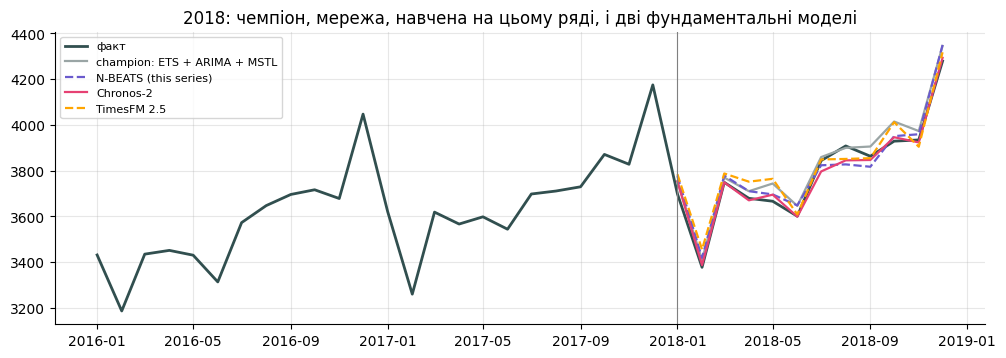

In [17]:
test5 = {name: np.asarray(f(past5, H5)) for name, f in forecasters5.items()}
test5["champion + Chronos-2"] = (test5["champion: ETS + ARIMA + MSTL"] + test5["Chronos-2"]) / 2
mase5 = pd.Series({name: np.mean(np.abs(y5[-H5:] - f)) / scale5 for name, f in test5.items()}, name="MASE in 2018")
result5 = pd.DataFrame({"windows 2014–2017": table5["mean"], "2018": mase5})
display(scoreboard(result5))

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(cafes["ds"].iloc[-36:], y5[-36:], color=COLOURS["actual"], linewidth=2, label="факт")
for name, colour, style_ in [("champion: ETS + ARIMA + MSTL", COLOURS["old"], "-"), ("N-BEATS (this series)", COLOURS["nn"], "--"),
                             ("Chronos-2", COLOURS["fm"], "-"), ("TimesFM 2.5", COLOURS["c"], "--")]:
    ax.plot(cafes["ds"].iloc[-H5:], test5[name], style_, color=colour, linewidth=1.6, label=name)
ax.axvline(cafes["ds"].iloc[-H5], color="grey", linewidth=0.8)
ax.set_title("2018: чемпіон, мережа, навчена на цьому ряді, і дві фундаментальні моделі")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**📌 Що сталося у 2018 році.**

- **Chronos-2 — 0,22, майже вдвічі краще за чемпіона (0,41).** Таблиця вікон цього не передбачала: там вони були рівні (0,53 проти 0,54).
- **Суміш «чемпіон + Chronos-2» — друга (0,27).** Найкраща на вікнах і друга в тесті: саме такої поведінки чекаємо від середнього.
- **N-BEATS** зі слабких вікон (0,61) піднялася до рівня чемпіона (0,41), **MLP** пішла навпаки (0,54 → 0,57). Один рік — це одна спроба, а не вирок.
- **LSTM** і тут найгірша (1,30).

**❓ Питання.** Якби ви були аналітиком цієї галузі й мали обрати один прогнозист на наступні п'ять
років, який би це був — і що б ви перевіряли щороку?

**📌 Відповідь.** Розумний вибір — **«чемпіон + Chronos-2»**: найкращий на вікнах, другий у 2018 році, дешевий і не залежить від того, котра з моделей цього року в ударі. Обрати сам Chronos-2 через 0,22 у 2018 році — це вибір за тестом.

Що перевіряти щороку:

- **ковзні вікна заново**, з новим роком у таблиці: чи не почала одна з частин систематично програвати;
- **версію моделі**: фундаментальні моделі оновлюються, і нова версія — це нова модель, яку треба перевірити заново;
- **покриття інтервалу** на фактичних даних року;
- **корпус**: чи не з'явилися ваші дані (або їхнє джерело) в навчальних даних нової версії.

## Що взяти з собою на сьогоднішню лабораторну

- **Фундаментальна модель — ще один кандидат.** Зазвичай сильний і дешевий у спробі: кілька рядків, жодного
  навчання. Оцінюйте її на тих самих ковзних вікнах, що й усе інше.
- **Перевірте корпус, перш ніж вірити оцінці.** Модель, яка бачила ваші дані або їхнє джерело, не прогнозує
  zero-shot. Дивіться картку моделі й статтю; якщо вони мовчать — так і напишіть.
- **Нейромережа, навчена на одному короткому ряді**, рідко обіграє ETS чи ARIMA: їй є з чого вчитися лише на
  кількох сотнях чисел. N-BEATS прославилася навчанням на багатьох рядах одразу.
- **Інтервали:** покриття разом із Вінклером, ніколи лише покриття.
- **Старі уроки досі працюють:** обирайте на валідаційних вікнах, а не на тесті; середнє різних моделей —
  дешева страховка.